# Classificação de Risco na Gravidez

## 1. Definição do problema

**Objetivo: classificar o **RiskLevel** de gestantes em **`low risk`, `mid risk` e `high risk`** a partir de seis atributos clínicos.**

É um problema de classificação multiclasse supervisionada.

--

## 1.1. Carregamento dos dados

Nesta etapa foi feito o **carregamento da base, dimensões e estrutura inicial**.

In [105]:
# Bibliotecas iniciais
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Montar o Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Caminho da base de dados no Meu Drive
base = "data/maternal_health_risk_subbase_4.csv"

# Carregamento da base de dados
df = pd.read_csv(base)

# Visualização inicial
display(df.head())

print("Dimensão da base:", df.shape)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate,RiskLevel
0,25,120,90,7.5,101.0,80,low risk
1,25,100,90,7.5,98.0,76,low risk
2,21,90,60,6.9,98.0,86,mid risk
3,17,85,60,6.3,102.0,86,high risk
4,25,140,100,7.5,98.0,80,high risk


Dimensão da base: (92, 7)


- Base: **92 registros e 7 colunas. (6 features númericas / preditores e 1 variável alvo com 3 classes)**
- **Preditores:** `Age`, `SystolicBP`, `DiastolicBP`, `BS`, `BodyTemp` e `HeartRate`.
- **Alvo:** `RiskLevel`.



## 2. Verificação da qualidade e estrutura dos dados

**Foram verificados tipos, valores ausentes, duplicidades e possíveis inconsistências entre atributos e classes.**

**Duplicatas exatas serão removidas** antes do split para evitar observações idênticas em treino e teste.

**Casos com os mesmos atributos, mas classes diferentes, serão mantidos** por representarem possível sobreposição entre classes.

In [106]:
# Resumo dos tipos e valores ausentes
resumo_qualidade = pd.DataFrame({
    "Tipo": df.dtypes,
    "Valores ausentes": df.isnull().sum()
})

display(resumo_qualidade)

# Estatísticas descritivas
estatisticas = df.describe().T

def destacar_valores(data):
    estilo = pd.DataFrame(
        "",
        index=data.index,
        columns=data.columns
    )

    # Age: mínimo e máximo
    estilo.loc["Age", "min"] = "font-weight: bold; background-color: #dbeafe;"
    estilo.loc["Age", "max"] = "font-weight: bold; background-color: #dbeafe;"

    # BS: mínimo e máximo
    estilo.loc["BS", "min"] = "font-weight: bold; background-color: #dbeafe;"
    estilo.loc["BS", "max"] = "font-weight: bold; background-color: #dbeafe;"

    return estilo

display(
    estatisticas.style
    .apply(destacar_valores, axis=None)
    .format("{:.2f}")
)
# Verificação de registros exatamente duplicados
duplicados = df.duplicated().sum()

print(f"\nRegistros duplicados: {duplicados}")

# Verificação de combinações iguais de atributos com classes diferentes
atributos = [
    "Age",
    "SystolicBP",
    "DiastolicBP",
    "BS",
    "BodyTemp",
    "HeartRate"
]

conflitos = (
    df.groupby(atributos)["RiskLevel"]
      .agg(lambda x: sorted(x.unique()))
      .reset_index(name="Classes")
)

conflitos = conflitos[conflitos["Classes"].str.len() > 1]

print(f"\nCombinações de atributos associadas a mais de uma classe: {len(conflitos)}")

# if len(conflitos) > 0:
#     display(conflitos)

# Exibir os registros originais envolvidos nos conflitos de classificação
registros_conflitantes = df.merge(
    conflitos[atributos],
    on=atributos,
    how="inner"
).sort_values(atributos)

display(registros_conflitantes)

# Remoção apenas dos registros exatamente duplicados
df = df.drop_duplicates().reset_index(drop=True)

print(f"\nDimensão da base após remoção das duplicidades: {df.shape}")

#df.to_csv("maternal_health_risk_limpo.csv", index=False, sep=";")


,Tipo,Valores ausentes
Age,int64,0
SystolicBP,int64,0
DiastolicBP,int64,0
BS,float64,0
BodyTemp,float64,0
HeartRate,int64,0
RiskLevel,object,0


,count,mean,std,min,25%,50%,75%,max
Age,92.00,31.01,13.94,12.00,20.00,28.00,40.00,60.00
SystolicBP,92.00,114.80,19.10,75.00,100.00,120.00,122.50,160.00
DiastolicBP,92.00,77.38,14.31,49.00,65.00,80.00,90.00,100.00
BS,92.00,8.93,3.45,6.00,6.90,7.50,9.00,19.00
BodyTemp,92.00,98.79,1.40,98.00,98.00,98.00,98.50,102.00
HeartRate,92.00,75.71,7.66,60.00,70.00,76.00,80.00,90.00



Registros duplicados: 12

Combinações de atributos associadas a mais de uma classe: 3


,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate,RiskLevel
0,19,120,80,7.0,98.0,70,low risk
4,19,120,80,7.0,98.0,70,mid risk
7,19,120,80,7.0,98.0,70,mid risk
8,19,120,80,7.0,98.0,70,mid risk
9,19,120,80,7.0,98.0,70,mid risk
1,31,120,60,6.1,98.0,76,mid risk
3,31,120,60,6.1,98.0,76,low risk
2,50,130,100,16.0,98.0,75,high risk
5,50,130,100,16.0,98.0,75,mid risk
6,50,130,100,16.0,98.0,75,mid risk



Dimensão da base após remoção das duplicidades: (80, 7)


- Todos os atributos numéricos têm 92 observações, então não há valores ausentes nessas colunas.
- Há escalas bem diferentes entre as features: por exemplo, **Age vai de 12 a 60 (o que isoladamente pode não indicar ao modelo um risco alto, caso clinicamente seja interpretado assim)**, BS de 6 a 19 e SystolicBP de 75 a 160. Isso ajuda a justificar depois a padronização usada no SVM.
- BodyTemp apresenta baixa variabilidade, concentrada em torno de 98, enquanto Age, pressão arterial e BS apresentam maior dispersão.
- Não há valores ausentes.
- Foram removidas 12 duplicatas exatas: a base passou de **92 para 80 registros**.
- Foram encontradas 3 combinações de atributos associadas a classes diferentes.

Isso sugere sobreposição entre as classes: os seis atributos podem não separar perfeitamente todos os casos.

## 3. Distribuição das classes e avaliação do desbalanceamento

Será avaliada a distribuição de `RiskLevel` e o **Imbalance Ratio (IR)**.

O objetivo é verificar se existe desbalanceamento suficiente para justificar algum tratamento adicional de viés.

,Quantidade,Percentual (%)
RiskLevel,,
low risk,33,41.25
mid risk,24,30.00
high risk,23,28.75


Maior classe: 33 registros
Menor classe: 23 registros
Imbalance Ratio (IR): 1.43


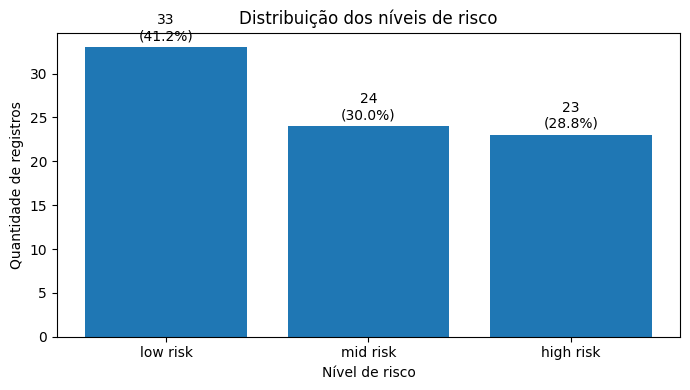

In [107]:
# Ordem das classes para facilitar a interpretação
ordem_classes = ["low risk", "mid risk", "high risk"]

# Quantidade e percentual de registros por classe
quantidade = df["RiskLevel"].value_counts().reindex(ordem_classes)
percentual = (
    df["RiskLevel"]
    .value_counts(normalize=True)
    .reindex(ordem_classes)
    * 100
)

distribuicao = pd.DataFrame({
    "Quantidade": quantidade,
    "Percentual (%)": percentual.round(2)
})

display(distribuicao)

# Cálculo do Imbalance Ratio (IR)
maior_classe = quantidade.max()
menor_classe = quantidade.min()

ir = maior_classe / menor_classe

print(f"Maior classe: {maior_classe} registros")
print(f"Menor classe: {menor_classe} registros")
print(f"Imbalance Ratio (IR): {ir:.2f}")

# Representação gráfica
fig, ax = plt.subplots(figsize=(7, 4))

barras = ax.bar(
    distribuicao.index,
    distribuicao["Quantidade"]
)

ax.set_title("Distribuição dos níveis de risco")
ax.set_xlabel("Nível de risco")
ax.set_ylabel("Quantidade de registros")

# Exibe quantidade e percentual acima das barras
rotulos = [
    f"{q}\n({p:.1f}%)"
    for q, p in zip(
        distribuicao["Quantidade"],
        distribuicao["Percentual (%)"]
    )
]

ax.bar_label(barras, labels=rotulos, padding=3)

plt.tight_layout()
plt.show()

### Análise da etapa

- `low risk`: **33 (41,25%)**
- `mid risk`: **24 (30,00%)**
- `high risk`: **23 (28,75%)**
- **IR = 33/23 = 1,43**

Não há assimetria acentuada entre as classes; por isso, não aplicamos  balanceamento artificial.

## 4. Análise exploratória dos atributos por nível de risco

Foram avaliados **valores médios** e a **distribuição** em boxplots dos seis atributos entre as três classes.

A ideia é identificar padrões visuais e sobreposições antes de treinar os modelos.

Média dos atributos por nível de risco:


,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate
RiskLevel,,,,,,
low risk,26.09,108.06,74.91,7.20,98.48,73.73
mid risk,34.00,112.50,72.50,8.17,99.00,76.17
high risk,36.57,128.70,86.09,12.00,98.91,78.52


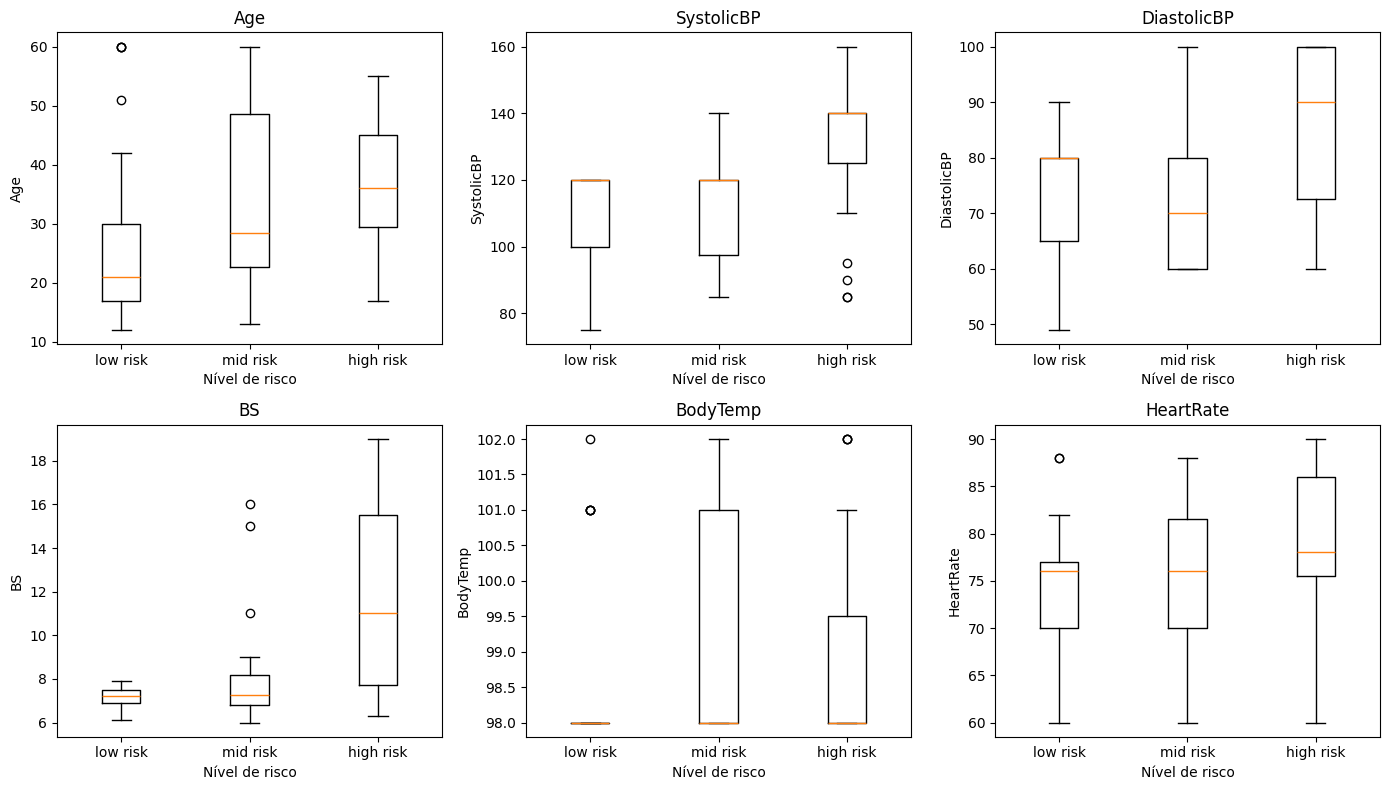

In [108]:
# Atributos preditores
atributos = [
    "Age",
    "SystolicBP",
    "DiastolicBP",
    "BS",
    "BodyTemp",
    "HeartRate"
]

ordem_classes = ["low risk", "mid risk", "high risk"]

# Média dos atributos por classe
medias_classes = (
    df.groupby("RiskLevel")[atributos]
      .mean()
      .reindex(ordem_classes)
      .round(2)
)

print("Média dos atributos por nível de risco:")
display(medias_classes)

# Boxplots dos atributos por classe
fig, axes = plt.subplots(2, 3, figsize=(14, 8))

for ax, atributo in zip(axes.flatten(), atributos):

    dados_boxplot = [
        df.loc[df["RiskLevel"] == classe, atributo]
        for classe in ordem_classes
    ]

    ax.boxplot(
        dados_boxplot,
        tick_labels=ordem_classes
    )

    ax.set_title(atributo)
    ax.set_xlabel("Nível de risco")
    ax.set_ylabel(atributo)

plt.tight_layout()
plt.show()

- `Age` média aumenta progressivameente, entre as classes `low`, `mid` e `high risk`.
- `SystolicBP`, `DiastolicBP` e `BS` apresentam diferenças mais visíveis para `high risk`.
- `BodyTemp` e `HeartRate` mostram maior sobreposição.

**A classificação provavelmente depende da combinação de atributos, e não de uma única variável.**

### **4.1. Correlação entre os atributos**

A matriz de correlação verifica relações entre os preditores.

Correlação indica associação entre variáveis, não causalidade nem importância para o modelo.

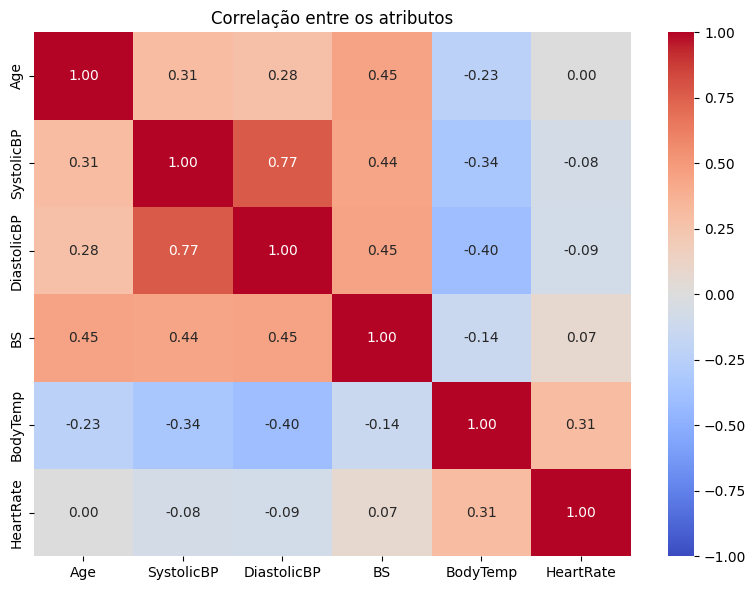

In [109]:
import seaborn as sns

correlacao = df[atributos].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlacao,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Correlação entre os atributos")
plt.tight_layout()
plt.show()

### Análise da correlação

- `SystolicBP × DiastolicBP`: **0,77** (positiva forte)
- `BS × SystolicBP`: **0,44** (moderada)
- `BS × DiastolicBP`: **0,45**
- `Age × BS`: **0,45**

**Há informação parcialmente compartilhada entre alguns atributos, principalmente entre as medidas de pressão arterial.**

## 5. Preparação dos dados e separação entre **treino e teste**

Preditores: os seis atributos numéricos.  
Alvo: `RiskLevel`.

Divisão estratificada:
- **80% treinamento**
- **20% teste**

**O teste fica reservado para a avaliação final; a otimização usa apenas o treinamento.**

In [110]:
from sklearn.model_selection import train_test_split
import pandas as pd

# Separação dos atributos preditores e da variável alvo
X = df[
    [
        "Age",
        "SystolicBP",
        "DiastolicBP",
        "BS",
        "BodyTemp",
        "HeartRate"
    ]
]

y = df["RiskLevel"]

# Divisão estratificada entre treinamento e teste
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y #estratificação (proporcionalidade)
)

# Dimensões dos conjuntos
print("Dimensão de X (preditores):", X.shape)
print("Dimensão de y (variável alvo):", y.shape)

print("\nConjunto de treinamento:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nConjunto de teste:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

# Ordem das classes
ordem_classes = ["low risk", "mid risk", "high risk"]

# Distribuição absoluta e percentual das classes

base_abs = y.value_counts().reindex(ordem_classes)
base_pct = (
    y.value_counts(normalize=True)
    .reindex(ordem_classes)
    .mul(100)
)

treino_abs = y_train.value_counts().reindex(ordem_classes)
treino_pct = (
    y_train.value_counts(normalize=True)
    .reindex(ordem_classes)
    .mul(100)
)

teste_abs = y_test.value_counts().reindex(ordem_classes)
teste_pct = (
    y_test.value_counts(normalize=True)
    .reindex(ordem_classes)
    .mul(100)
)

# Montagem da tabela comparativa
comparacao_distribuicao = pd.DataFrame({
    "Base completa": base_abs,
    "Base completa (%)": base_pct.round(2),
    "Treinamento": treino_abs,
    "Treinamento (%)": treino_pct.round(2),
    "Teste": teste_abs,
    "Teste (%)": teste_pct.round(2)
})

# Adiciona linha de total
comparacao_distribuicao.loc["Total"] = [
    int(base_abs.sum()),
    round(base_pct.sum(), 2),
    int(treino_abs.sum()),
    round(treino_pct.sum(), 2),
    int(teste_abs.sum()),
    round(teste_pct.sum(), 2)
]

print("\nDistribuição das classes:")
display(comparacao_distribuicao)

Dimensão de X (preditores): (80, 6)
Dimensão de y (variável alvo): (80,)

Conjunto de treinamento:
X_train: (64, 6)
y_train: (64,)

Conjunto de teste:
X_test: (16, 6)
y_test: (16,)

Distribuição das classes:


,Base completa,Base completa (%),Treinamento,Treinamento (%),Teste,Teste (%)
RiskLevel,,,,,,
low risk,33.0,41.25,27.0,42.19,6.0,37.50
mid risk,24.0,30.00,19.0,29.69,5.0,31.25
high risk,23.0,28.75,18.0,28.12,5.0,31.25
Total,80.0,100.00,64.0,100.00,16.0,100.00


- Treinamento: **64 registros (80%)**
- Teste: **16 registros (20%)**
- Estratificação preserva aproximadamente a proporção das três classes nos dois conjuntos, garantindo que estejam representadas tanto no treinamento quanto no teste.

### Por que utilizar 80/20?

**Como a base é pequena, com apenas 80 observações, foi priorizado mais dados para treinamento:**

- 80/20 → **64 treino / 16 teste**
- 75/25 → 60 treino / 20 teste


## 6. Estratégia de validação

Usamos **Stratified K-Fold com 5 folds** apenas no conjunto de treinamento.

A cada rodada: 4 folds treinam e 1 valida, preservando aproximadamente a proporção das classes.

In [111]:
from sklearn.model_selection import StratifiedKFold, GridSearchCV

# Configuração da validação cruzada estratificada
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Métrica que será utilizada para selecionar os melhores hiperparâmetros
metrica_otimizacao = "f1_macro"

print("Estratégia de validação:")
print("- Stratified K-Fold")
print("- Número de folds:", cv.get_n_splits())
print("- Métrica de otimização:", metrica_otimizacao)

# Verificação da distribuição das classes em cada fold de validação
distribuicao_folds = []

for numero_fold, (_, indice_validacao) in enumerate(
    cv.split(X_train, y_train),
    start=1
):
    y_validacao = y_train.iloc[indice_validacao]

    contagem = (
        y_validacao.value_counts()
        .reindex(ordem_classes, fill_value=0)
    )

    distribuicao_folds.append({
        "Fold": numero_fold,
        "Total": len(y_validacao),
        "low risk": contagem["low risk"],
        "mid risk": contagem["mid risk"],
        "high risk": contagem["high risk"]
    })

distribuicao_folds = pd.DataFrame(distribuicao_folds)

print("\nDistribuição das classes nos folds de validação:")
display(distribuicao_folds)

Estratégia de validação:
- Stratified K-Fold
- Número de folds: 5
- Métrica de otimização: f1_macro

Distribuição das classes nos folds de validação:


,Fold,Total,low risk,mid risk,high risk
0,1,13,5,4,4
1,2,13,5,4,4
2,3,13,5,4,4
3,4,13,6,4,3
4,5,12,6,3,3


**A validação cruzada estratificada com 5 folds foi escolhida para equilibrar tamanho de treino, validação e representação das três classes.**

Com menos folds, validamos com grupos maiores, mas treinamos com menos dados em cada rodada. Com mais folds, treinamos com mais dados, porém a validação fica menor e pode ficar mais sensível. O k=5 foi escolhido como equilíbrio.

Métrica de seleção: **F1 Macro**.  

## 7. Classificação 1: Árvore de Decisão — baseline

Primeiro modelo: **Decision Tree com parâmetros padrão.**

Esse algoritmo constrói uma estrutura hierárquica de decisões a partir dos atributos, realizando divisões sucessivas dos dados de forma a aumentar a separação entre as classes.

**Objetivo do baseline: criar uma referência antes da otimização e observar possível overfitting.**

In [112]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_validate

# Criação da Árvore de Decisão com parâmetros padrão
modelo_arvore_base = DecisionTreeClassifier(
    random_state=42
)

# Métricas utilizadas na validação cruzada
metricas = {
    "accuracy": "accuracy",
    "f1_macro": "f1_macro"
}

# Validação cruzada utilizando somente o conjunto de treinamento
resultados_cv = cross_validate(
    modelo_arvore_base,
    X_train,
    y_train,
    cv=cv, #StratifiedKFold, atribuído células acima
    scoring=metricas,
    return_train_score=True
)

# Resultados de cada fold
resultados_folds = pd.DataFrame({
    "Fold": range(1, 6),
    "Accuracy treino": resultados_cv["train_accuracy"],
    "Accuracy validação": resultados_cv["test_accuracy"],
    "F1 Macro treino": resultados_cv["train_f1_macro"],
    "F1 Macro validação": resultados_cv["test_f1_macro"]
})

display(resultados_folds.round(3))

# Médias dos resultados
print("\nResultados médios da validação cruzada")

print(
    f"\nAccuracy - treino: "
    f"{resultados_cv['train_accuracy'].mean():.3f}"
)

print(
    f"Accuracy - validação: "
    f"{resultados_cv['test_accuracy'].mean():.3f}"
)

print(
    f"\nF1 Macro - treino: "
    f"{resultados_cv['train_f1_macro'].mean():.3f}"
)

print(
    f"F1 Macro - validação: "
    f"{resultados_cv['test_f1_macro'].mean():.3f}"
)

print(
    f"\nDesvio padrão do F1 Macro na validação: "
    f"{resultados_cv['test_f1_macro'].std():.3f}"
)

# Treinamento do modelo com todo o conjunto de treinamento
# apenas para observar a complexidade da árvore gerada
modelo_arvore_base.fit(X_train, y_train)

print("\nComplexidade da árvore:")
print("Profundidade:", modelo_arvore_base.get_depth())
print("Número de folhas:", modelo_arvore_base.get_n_leaves())

,Fold,Accuracy treino,Accuracy validação,F1 Macro treino,F1 Macro validação
0,1,0.961,0.692,0.957,0.636
1,2,0.980,0.615,0.981,0.617
2,3,0.980,0.385,0.977,0.369
3,4,1.000,0.615,1.000,0.588
4,5,0.962,0.667,0.959,0.638



Resultados médios da validação cruzada

Accuracy - treino: 0.977
Accuracy - validação: 0.595

F1 Macro - treino: 0.975
F1 Macro - validação: 0.570

Desvio padrão do F1 Macro na validação: 0.102

Complexidade da árvore:
Profundidade: 12
Número de folhas: 24


**Acurácia:** Proporção de acertos.

**F1:** Desempenho médio em cada classe, com o mesmo peso.

- F1 Macro treino: **≈ 0,97** (desempenho muito elevado )
- F1 Macro validação: **≈ 0,57** (que com oscilações entre folds)
- Profundidade: **12**

**A grande diferença entre treino e validação indica possível overfitting.**

**A árvore atingiu profundidade elevada e criou diversas folhas, permitindo divisões bastante específicas dos dados.**

## 8. Otimização dos hiperparâmetros da Árvore de Decisão

Nesta etapa será realizada a otimização dos hiperparâmetros utilizando Grid Search com validação cruzada estratificada.

**O Grid Search testa diferentes combinações de valores para cada hiperparâmetro** e avalia cada configuração utilizando os 5 folds do conjunto de treinamento.

Serão avaliados os seguintes hiperparâmetros:

- `criterion`: critério utilizado para medir a qualidade das divisões da árvore;
- `max_depth`: profundidade máxima permitida para a árvore;
- `min_samples_split`: quantidade mínima de registros necessária para dividir um nó;
- `min_samples_leaf`: quantidade mínima de registros que deve permanecer em uma folha.

In [113]:
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier

# Modelo que será otimizado
modelo_arvore = DecisionTreeClassifier(
    random_state=42
)

# Grade de hiperparâmetros - teremos 2×6×3×3=108 combinações x5 folds = 540 avaliações por validação cruzada. Aumentar gera custo computacional, é preciso avaliar.
parametros_arvore = {
    "criterion": ["gini", "entropy"], #testar 2 critérios de divisão
    "max_depth": [2, 3, 4, 5, 6, None], #controle de crescimento da árvore e possível overfiting (none sem limite explicíto)
    "min_samples_split": [2, 4, 6], #2 é a configuração mais permissiva; valores maiores tornam a árvore mais conservadora, exigindo mais exemplos antes de dividir um nó.
    "min_samples_leaf": [1, 2, 4] #verifica se exigir mais observações em cada folha melhora a generalização.
}

# Configuração do Grid Search
grid_arvore = GridSearchCV( #testa sistematicamente todas as combinações fornecidas.
    estimator=modelo_arvore,
    param_grid=parametros_arvore,
    scoring="f1_macro",
    cv=cv, #StratifiedKFold, atribuído células acima
    n_jobs=-1, #permite que o Grid Search utilize todos os núcleos disponíveis do processador, acelerando a busca pelos melhores hiperparâmetros.
    return_train_score=True
)

# Otimização utilizando somente o conjunto de treinamento
grid_arvore.fit(X_train, y_train)

# Melhor configuração encontrada
print("Melhores hiperparâmetros:")
print(grid_arvore.best_params_)

print(
    f"\nMelhor F1 Macro médio na validação cruzada: "
    f"{grid_arvore.best_score_:.3f}"
)

# Recupera o melhor modelo encontrado pelo Grid Search
melhor_arvore = grid_arvore.best_estimator_

print("\nComplexidade da árvore otimizada:")
print("Profundidade:", melhor_arvore.get_depth())
print("Número de folhas:", melhor_arvore.get_n_leaves())

# Comparação entre baseline e modelo otimizado
f1_base = resultados_cv["test_f1_macro"].mean()
f1_otimizado = grid_arvore.best_score_

comparacao_arvore = pd.DataFrame({
    "Modelo": [
        "Árvore baseline",
        "Árvore otimizada"
    ],
    "F1 Macro médio - validação": [
        f1_base,
        f1_otimizado
    ]
})

display(comparacao_arvore.round(3))

Melhores hiperparâmetros:
{'criterion': 'gini', 'max_depth': 4, 'min_samples_leaf': 1, 'min_samples_split': 4}

Melhor F1 Macro médio na validação cruzada: 0.590

Complexidade da árvore otimizada:
Profundidade: 4
Número de folhas: 11


,Modelo,F1 Macro médio - validação
0,Árvore baseline,0.57
1,Árvore otimizada,0.59


Resultados:
- F1 Macro CV: **0,590**
- Profundidade: **12 → 4**
- Folhas: **24 → 11**

**A melhora foi pequena no F1, mas a árvore ficou muito mais simples e interpretável.**

## 8.1. Regras da Árvore de Decisão

A árvore otimizada tem profundidade **4** e **11 folhas**, permitindo observar diretamente seus principais caminhos.

As regras mostram quais atributos e cortes foram usados para separar as classes.

Os valores encontrados são padrões desta base, **não critérios clínicos**.

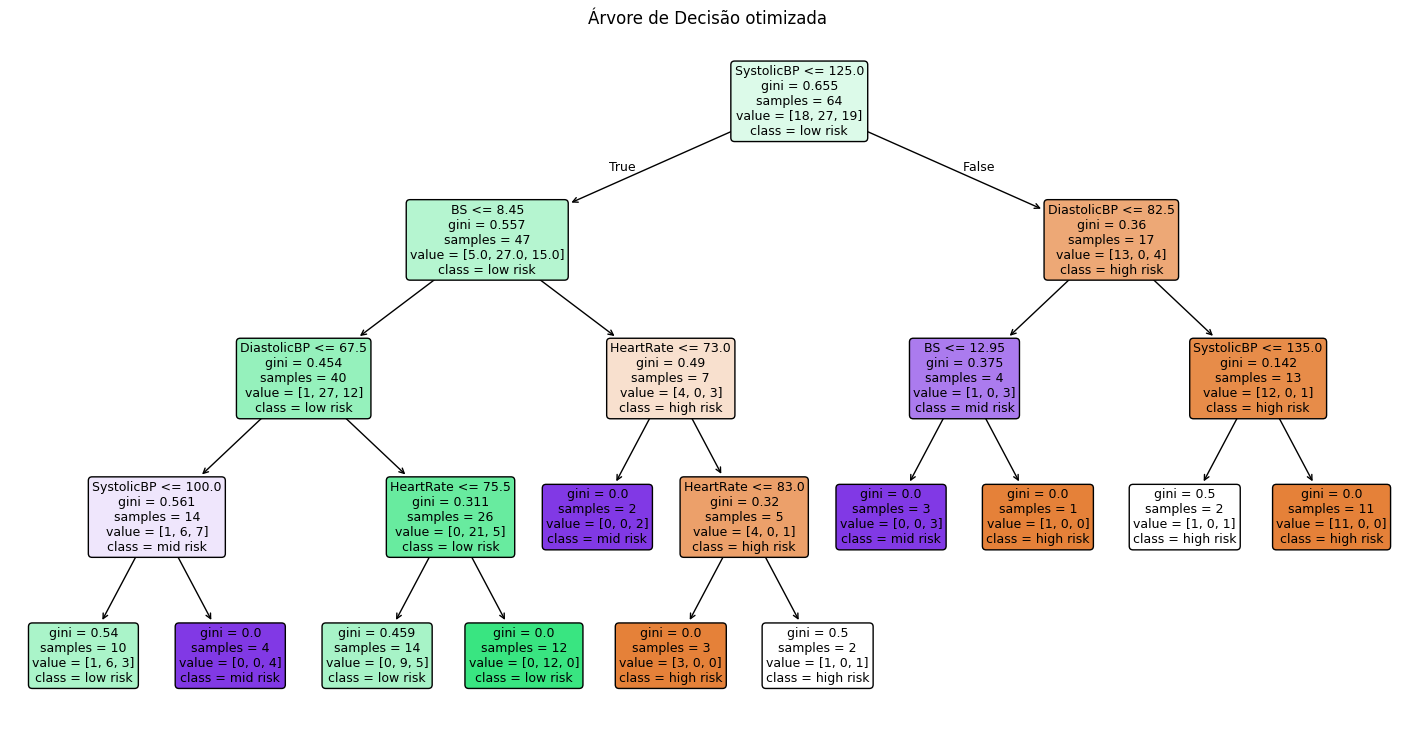

In [114]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(18, 9))

plot_tree(
    melhor_arvore,
    feature_names=X_train.columns,
    class_names=melhor_arvore.classes_,
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title("Árvore de Decisão otimizada")
plt.show()

Entre os padrões encontrados pelo modelo, destacam-se:

- para `SystolicBP <= 125` e `BS <= 8,45`, as classificações são predominantemente `low risk` ou `mid risk`, dependendo das demais condições;

- Embora `Age` tenha apresentado uma tendência visual clara na análise exploratória, esse atributo não foi utilizado pela Árvore de Decisão otimizada.

- As regras extraídas representam padrões aprendidos pelo modelo a partir desta base específica e não devem ser interpretadas como limites ou critérios clínicos.

## 9. Classificação 2: Random Forest — baseline

Segundo modelo: **Random Forest, ensemble (combinação) de várias árvores.**

A expectativa é reduzir a variância de uma árvore isolada como na Árvore de Decisão e obter maior estabilidade.

In [115]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_validate

# Criação do Random Forest com parâmetros padrão (100 árvores)
modelo_rf_base = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

# Validação cruzada utilizando somente o conjunto de treinamento
resultados_rf_cv = cross_validate(
    modelo_rf_base,
    X_train,
    y_train,
    cv=cv,
    scoring=metricas,
    return_train_score=True
)

# Resultados por fold
resultados_rf_folds = pd.DataFrame({
    "Fold": range(1, 6),
    "Accuracy treino": resultados_rf_cv["train_accuracy"],
    "Accuracy validação": resultados_rf_cv["test_accuracy"],
    "F1 Macro treino": resultados_rf_cv["train_f1_macro"],
    "F1 Macro validação": resultados_rf_cv["test_f1_macro"]
})

display(resultados_rf_folds.round(3))

# Resultados médios
print("\nResultados médios da validação cruzada")

print(
    f"\nAccuracy - treino: "
    f"{resultados_rf_cv['train_accuracy'].mean():.3f}"
)

print(
    f"Accuracy - validação: "
    f"{resultados_rf_cv['test_accuracy'].mean():.3f}"
)

print(
    f"\nF1 Macro - treino: "
    f"{resultados_rf_cv['train_f1_macro'].mean():.3f}"
)

print(
    f"F1 Macro - validação: "
    f"{resultados_rf_cv['test_f1_macro'].mean():.3f}"
)

print(
    f"\nDesvio padrão do F1 Macro na validação: "
    f"{resultados_rf_cv['test_f1_macro'].std():.3f}"
)

# Treinamento com todo o conjunto de treinamento
# para observar algumas características do modelo
modelo_rf_base.fit(X_train, y_train)

print("\nCaracterísticas do Random Forest baseline:")
print("Número de árvores:", modelo_rf_base.n_estimators)

profundidades = [
    arvore.get_depth()
    for arvore in modelo_rf_base.estimators_
]

print(
    f"Profundidade média das árvores:"
    f"{np.mean(profundidades):.2f}"
)

,Fold,Accuracy treino,Accuracy validação,F1 Macro treino,F1 Macro validação
0,1,0.961,0.462,0.957,0.422
1,2,0.980,0.692,0.981,0.695
2,3,0.980,0.385,0.977,0.370
3,4,1.000,0.692,1.000,0.639
4,5,0.962,0.583,0.959,0.583



Resultados médios da validação cruzada

Accuracy - treino: 0.977
Accuracy - validação: 0.563

F1 Macro - treino: 0.975
F1 Macro - validação: 0.542

Desvio padrão do F1 Macro na validação: 0.125

Características do Random Forest baseline:
Número de árvores: 100
Profundidade média das árvores:9.05


- F1 Macro treino: **0,975**
- F1 Macro validação: **0,542**
- Profundidade média: **≈ 9**

**Também houve forte diferença entre treino e validação, indicando possível overfitting.**

O baseline ficou abaixo da Árvore de Decisão.

## 10. Otimização do Random Forest



In [116]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

# Modelo que será otimizado
modelo_rf = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

# Grade de hiperparâmetros - 3×3×2×3×2=108 x5=540 avaliações por validação cruzada
parametros_rf = {
    "n_estimators": [50, 100, 200], #qtde árvores
    "max_depth": [3, 5, None], #limita o crescimento da árvore (profundidade)
    "min_samples_split": [2, 4], #samples: controlam o crescimento das árvores
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"] #determina quantos atributos podem ser considerados em cada divisão
    #parâmetros como class_weight não foram utilizados porque verificamos que a base não apresenta desbalanceamento acentuado
}

# Configuração do Grid Search
grid_rf = GridSearchCV(
    estimator=modelo_rf,
    param_grid=parametros_rf,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    return_train_score=True
)

# Otimização utilizando somente os dados de treinamento
grid_rf.fit(X_train, y_train)

# Melhor configuração encontrada
print("Melhores hiperparâmetros:")
print(grid_rf.best_params_)

print(
    f"\nMelhor F1 Macro médio na validação cruzada: "
    f"{grid_rf.best_score_:.3f}"
)

# Melhor modelo
melhor_rf = grid_rf.best_estimator_

# Profundidade média das árvores da melhor floresta
profundidades_otimizado = [
    arvore.get_depth()
    for arvore in melhor_rf.estimators_
]

print("\nCaracterísticas do Random Forest otimizado:")
print("Número de árvores:", melhor_rf.n_estimators)

print(
    f"Profundidade média das árvores: "
    f"{np.mean(profundidades_otimizado):.2f}"
)

# Comparação baseline x otimizado
f1_rf_base = resultados_rf_cv["test_f1_macro"].mean()
f1_rf_otimizado = grid_rf.best_score_

comparacao_rf = pd.DataFrame({
    "Modelo": [
        "Random Forest baseline",
        "Random Forest otimizado"
    ],
    "F1 Macro médio - validação": [
        f1_rf_base,
        f1_rf_otimizado
    ]
})

display(comparacao_rf.round(3))

Melhores hiperparâmetros:
{'max_depth': 5, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 100}

Melhor F1 Macro médio na validação cruzada: 0.605

Características do Random Forest otimizado:
Número de árvores: 100
Profundidade média das árvores: 4.99


,Modelo,F1 Macro médio - validação
0,Random Forest baseline,0.542
1,Random Forest otimizado,0.605


Resultados:
- F1 Macro: **0,542 → 0,605**
- Profundidade média: **9,05 → 4,99**

**Até aqui, o Random Forest passou a ser o melhor modelo na validação cruzada.**

## 10.1. Importância dos atributos no Random Forest otimizado

O Random Forest permite medir a participação global dos atributos nas decisões do conjunto de árvores.

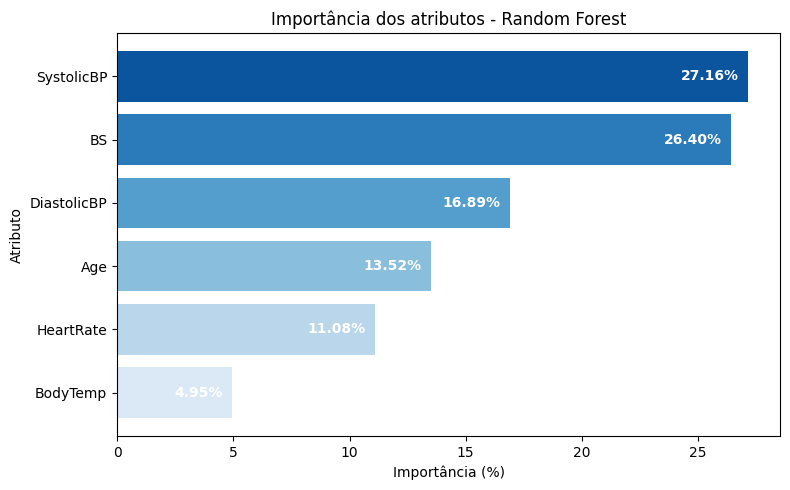

In [117]:
# Importância dos atributos no Random Forest otimizado

importancias = pd.DataFrame({
    "Atributo": X_train.columns,
    "Importância": melhor_rf.feature_importances_
})

# Ordenação da maior para a menor importância
importancias = (
    importancias
    .sort_values("Importância", ascending=False)
    .reset_index(drop=True)
)

# Percentual para facilitar a interpretação
importancias["Importância (%)"] = (
    importancias["Importância"] * 100
).round(2)

# Gráfico
import seaborn as sns
import matplotlib.pyplot as plt

# Paleta de cores
cores = sns.color_palette(
    "Blues",
    n_colors=len(importancias)
)

plt.figure(figsize=(8, 5))

barras = plt.barh(
    importancias["Atributo"][::-1],
    importancias["Importância (%)"][::-1],
    color=cores
)

# Percentuais dentro das barras
for barra, valor in zip(
    barras,
    importancias["Importância (%)"][::-1]
):
    plt.text(
        valor - 0.4,
        barra.get_y() + barra.get_height() / 2,
        f"{valor:.2f}%",
        va="center",
        ha="right",
        color="white",
        fontweight="bold"
    )

plt.xlabel("Importância (%)")
plt.ylabel("Atributo")
plt.title("Importância dos atributos - Random Forest")

plt.tight_layout()
plt.show()

**Pressão arterial e glicemia concentraram a maior participação no Random Forest, com 70,45%.**

`Age` teve baixa representatividade na importância global.

`BodyTemp` teve a menor importância (**4,95%**).

**As importâncias representam o modelo, não causalidade ou relevância clínica**.

## 11. Classificação 3: SVM — baseline

Terceiro modelo: **Support Vector Machine (SVM) com kernel RBF**.

**Como o SVM é sensível à escala, foi utilizado StandardScaler** antes da classificação.

In [118]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.model_selection import cross_validate

# Pipeline:
# 1. padronização dos atributos
# 2. classificação com SVM
modelo_svm_base = Pipeline([
    ("scaler", StandardScaler()),
    ("svc", SVC(
        kernel="rbf",
        random_state=42
    ))
])

# Validação cruzada utilizando o mesmo protocolo dos demais modelos
resultados_svm_cv = cross_validate(
    modelo_svm_base,
    X_train,
    y_train,
    cv=cv,
    scoring=metricas,
    return_train_score=True
)

# Resultados por fold
resultados_svm_folds = pd.DataFrame({
    "Fold": range(1, 6),
    "Accuracy treino": resultados_svm_cv["train_accuracy"],
    "Accuracy validação": resultados_svm_cv["test_accuracy"],
    "F1 Macro treino": resultados_svm_cv["train_f1_macro"],
    "F1 Macro validação": resultados_svm_cv["test_f1_macro"]
})

display(resultados_svm_folds.round(3))

# Resultados médios
print("\nResultados médios da validação cruzada")

print(
    f"\nAccuracy - treino: "
    f"{resultados_svm_cv['train_accuracy'].mean():.3f}"
)

print(
    f"Accuracy - validação: "
    f"{resultados_svm_cv['test_accuracy'].mean():.3f}"
)

print(
    f"\nF1 Macro - treino: "
    f"{resultados_svm_cv['train_f1_macro'].mean():.3f}"
)

print(
    f"F1 Macro - validação: "
    f"{resultados_svm_cv['test_f1_macro'].mean():.3f}"
)

print(
    f"\nDesvio padrão do F1 Macro na validação: "
    f"{resultados_svm_cv['test_f1_macro'].std():.3f}"
)

,Fold,Accuracy treino,Accuracy validação,F1 Macro treino,F1 Macro validação
0,1,0.765,0.462,0.735,0.422
1,2,0.765,0.615,0.728,0.602
2,3,0.706,0.538,0.646,0.413
3,4,0.725,0.538,0.663,0.361
4,5,0.750,0.417,0.748,0.398



Resultados médios da validação cruzada

Accuracy - treino: 0.742
Accuracy - validação: 0.514

F1 Macro - treino: 0.704
F1 Macro - validação: 0.439

Desvio padrão do F1 Macro na validação: 0.084


### Análise da etapa

- F1 Macro treino: **0,704**
- F1 Macro validação: **0,439**
- Desvio padrão: **0,084**

**O SVM padrão teve o pior desempenho médio comparado aos outros modelos, embora com menor variação entre folds.**

## 12. Otimização do SVM

Principais hiperparâmetros:
- `C`: penalização dos erros / regularização
- `gamma`: alcance da influência de cada observação


In [119]:
from sklearn.model_selection import GridSearchCV

# Grade de hiperparâmetros
# Um C pequeno permite mais regularização e uma fronteira mais simples. Um C maior penaliza mais fortemente erros no treinamento e pode produzir uma fronteira mais ajustada aos dados.
# 4 x 4 = 16 x 5 = 80 avaliações.
parametros_svm = {
    "svc__C": [0.1, 1, 10, 100],
    "svc__gamma": ["scale", 0.01, 0.1, 1]
}

# Grid Search utilizando o Pipeline já criado
grid_svm = GridSearchCV(
    estimator=modelo_svm_base,
    param_grid=parametros_svm,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    return_train_score=True
)

# Otimização somente com o conjunto de treinamento
grid_svm.fit(X_train, y_train)

# Melhor configuração
print("Melhores hiperparâmetros encontrados na grade avaliada:")
print(grid_svm.best_params_)

print(
    f"\nMelhor F1 Macro médio na validação cruzada: "
    f"{grid_svm.best_score_:.3f}"
)

# Recupera o melhor Pipeline encontrado
melhor_svm = grid_svm.best_estimator_

# Resultados da melhor configuração
indice_melhor = grid_svm.best_index_

f1_treino_otimizado = (
    grid_svm.cv_results_["mean_train_score"][indice_melhor]
)

desvio_validacao = (
    grid_svm.cv_results_["std_test_score"][indice_melhor]
)

print(
    f"F1 Macro médio no treinamento: "
    f"{f1_treino_otimizado:.3f}"
)

print(
    f"Desvio padrão do F1 Macro na validação: "
    f"{desvio_validacao:.3f}"
)

# Comparação baseline x otimizado
f1_svm_base = resultados_svm_cv["test_f1_macro"].mean()
f1_svm_otimizado = grid_svm.best_score_

comparacao_svm = pd.DataFrame({
    "Modelo": [
        "SVM baseline",
        "SVM otimizado"
    ],
    "F1 Macro médio - validação": [
        f1_svm_base,
        f1_svm_otimizado
    ]
})

display(comparacao_svm.round(3))

Melhores hiperparâmetros encontrados na grade avaliada:
{'svc__C': 100, 'svc__gamma': 0.01}

Melhor F1 Macro médio na validação cruzada: 0.627
F1 Macro médio no treinamento: 0.764
Desvio padrão do F1 Macro na validação: 0.127


,Modelo,F1 Macro médio - validação
0,SVM baseline,0.439
1,SVM otimizado,0.627


**Resultados:**

**O SVM passou a liderar a validação cruzada, superando os resultados obtidos pelos modelos anteriores.**

- Árvore de Decisão otimizada: **0,590**;
- Random Forest otimizado: **0,605**;
- SVM otimizado: **0,627**.


## 13. Avaliação final dos modelos

Vamos comparar os três modelos otimizados usando:
- Accuracy
- Balanced Accuracy
- Precision Macro
- **F1 Macro**
- Recall de `high risk`

**O F1 Macro permanece como métrica principal por equilibrar as três classes.**

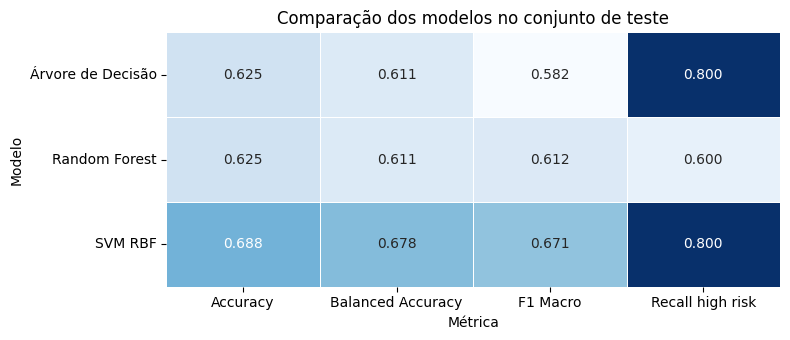

In [120]:
# Comparação visual dos modelos no conjunto de teste

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    recall_score,
    f1_score
)

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Previsões no conjunto de teste
pred_arvore = melhor_arvore.predict(X_test)
pred_rf = melhor_rf.predict(X_test)
pred_svm = melhor_svm.predict(X_test)

# Construção da tabela de resultados
resultados_teste = pd.DataFrame([
    {
        "Modelo": "Árvore de Decisão",
        "Accuracy": accuracy_score(y_test, pred_arvore),
        "Balanced Accuracy": balanced_accuracy_score(y_test, pred_arvore),
        "F1 Macro": f1_score(
            y_test, pred_arvore, average="macro", zero_division=0
        ),
        "Recall high risk": recall_score(
            y_test,
            pred_arvore,
            labels=["high risk"],
            average=None,
            zero_division=0
        )[0]
    },
    {
        "Modelo": "Random Forest",
        "Accuracy": accuracy_score(y_test, pred_rf),
        "Balanced Accuracy": balanced_accuracy_score(y_test, pred_rf),
        "F1 Macro": f1_score(
            y_test, pred_rf, average="macro", zero_division=0
        ),
        "Recall high risk": recall_score(
            y_test,
            pred_rf,
            labels=["high risk"],
            average=None,
            zero_division=0
        )[0]
    },
    {
        "Modelo": "SVM RBF",
        "Accuracy": accuracy_score(y_test, pred_svm),
        "Balanced Accuracy": balanced_accuracy_score(y_test, pred_svm),
        "F1 Macro": f1_score(
            y_test, pred_svm, average="macro", zero_division=0
        ),
        "Recall high risk": recall_score(
            y_test,
            pred_svm,
            labels=["high risk"],
            average=None,
            zero_division=0
        )[0]
    }
])

# Métricas usadas na comparação visual
metricas_comparacao = [
    "Accuracy",
    "Balanced Accuracy",
    "F1 Macro",
    "Recall high risk"
]

comparacao = (
    resultados_teste
    .set_index("Modelo")[metricas_comparacao]
)

# Heatmap
plt.figure(figsize=(8, 3.5))

sns.heatmap(
    comparacao,
    annot=True,
    fmt=".3f",
    cmap="Blues",
    linewidths=0.5,
    cbar=False
)

plt.title("Comparação dos modelos no conjunto de teste")
plt.xlabel("Métrica")
plt.ylabel("Modelo")

plt.tight_layout()
plt.show()

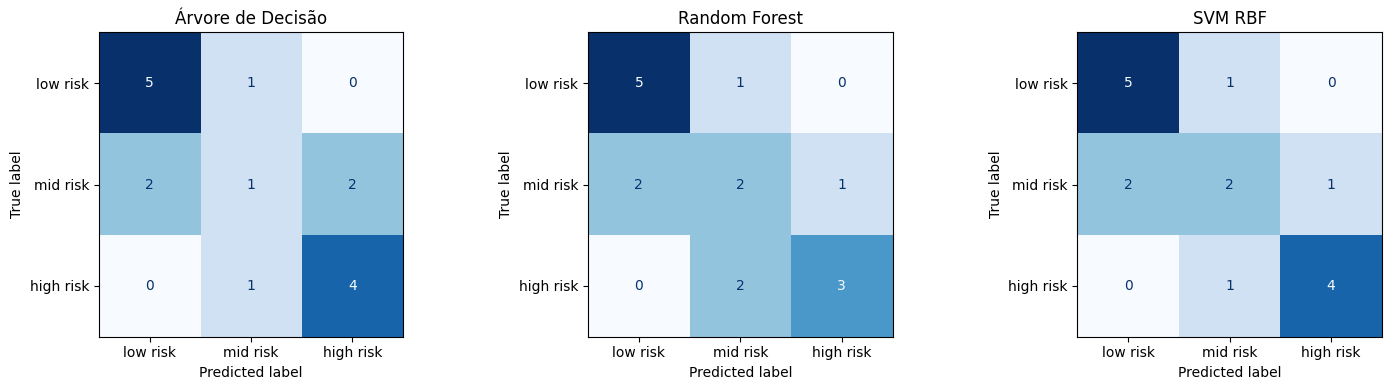

In [121]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

modelos_predicoes = {
    "Árvore de Decisão": pred_arvore,
    "Random Forest": pred_rf,
    "SVM RBF": pred_svm
}

for ax, (nome, predicao) in zip(axes, modelos_predicoes.items()):

    matriz = confusion_matrix(
        y_test,
        predicao,
        labels=ordem_classes
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=matriz,
        display_labels=ordem_classes
    )

    disp.plot(
        ax=ax,
        colorbar=False,
        cmap="Blues"
    )

    ax.set_title(nome)

plt.tight_layout()
plt.show()

**A classe `mid risk` foi a mais difícil para os três modelos.
Dos cinco casos reais de mid risk, os modelos acertaram apenas um ou dois.**

A diagonal principal mostra os acertos. Para a classe mid risk, tivemos:

Árvore de Decisão: 1 acerto em 5; recall 20%
Random Forest: 2 acertos em 5; recall 40%
SVM RBF: 2 acertos em 5; recall 40%

Enquanto low risk teve 5/6 acertos nos três modelos e high risk chegou a 4/5 na Árvore e no SVM.

**Como o teste possui só 16 casos, os resultados devem ser interpretados com cautela.**

## 14. Conclusões

- Base final: **80 registros**, após remover 12 duplicatas.
- Classes sem forte desbalanceamento: **IR = 1,43**.
- Split estratificado: **64 treino / 16 teste**.
- Otimização: **Grid Search + 5-fold estratificado + F1 Macro**.

### Resultado preditivo

F1 Macro no teste:
- DT: **0,582**
- RF: **0,612**
- SVM RBF: **0,671**

**O SVM RBF apresentou o melhor desempenho na validação cruzada e no teste.**

### Interpretação

- RF: destaque para `SystolicBP`, `BS` e `DiastolicBP`;
- DT: regras dominadas por pressão arterial e glicemia;
- SVM: os mesmos três atributos lideraram a Permutation Importance.

**O principal conhecimento extraído foi a convergência dos três modelos sobre pressão arterial e glicemia.**

### Limitações

- apenas **80 observações**;
- teste com **16 casos**;
- sobreposição entre classes;
- resultados exploratórios, sem interpretação causal ou clínica.

**Conclusão: o SVM foi o melhor classificador nesta amostra, enquanto os três modelos ofereceram interpretações complementares e consistentes.**



---




## 0. Importância dos atributos — SVM RBF

Como o SVM RBF não fornece regras ou coeficientes simples, usamos **Permutation Importance**.

A técnica embaralha um atributo e mede quanto o **F1 Macro cai**.

**Quanto maior a queda, maior a dependência do SVM daquele atributo.**

,Atributo,Importância,Desvio
0,BS,0.176,0.086
1,DiastolicBP,0.140,0.097
2,SystolicBP,0.121,0.087
3,Age,0.109,0.062
4,HeartRate,0.107,0.069
5,BodyTemp,0.092,0.056


Importância: quando BS é embaralhado, o F1 Macro cai em média 0,176 em relação ao desempenho original.


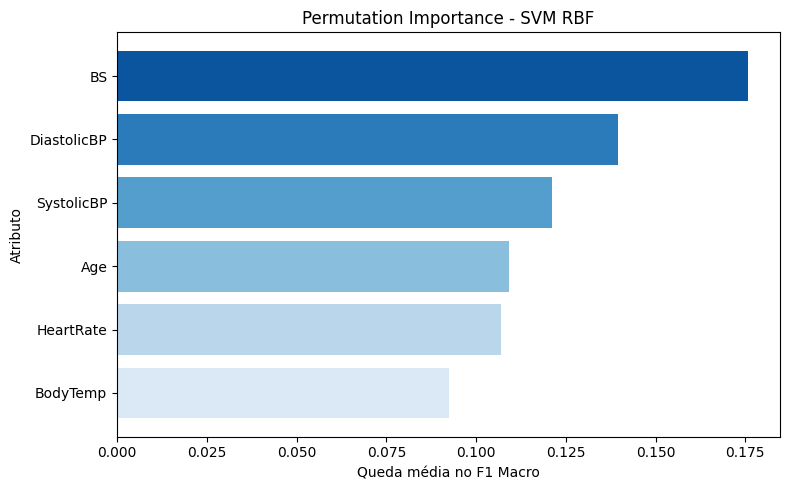

In [122]:
from sklearn.inspection import permutation_importance

importancia_svm = permutation_importance(
    melhor_svm,
    X_test,
    y_test,
    scoring="f1_macro",
    n_repeats=30,
    random_state=42,
    n_jobs=-1
)

importancias_svm = pd.DataFrame({
    "Atributo": X_test.columns,
    "Importância": importancia_svm.importances_mean,
    "Desvio": importancia_svm.importances_std
}).sort_values(
    "Importância",
    ascending=False
).reset_index(drop=True)

display(importancias_svm.round(3))

print("Importância: quando BS é embaralhado, o F1 Macro cai em média 0,176 em relação ao desempenho original.")

import seaborn as sns
import matplotlib.pyplot as plt

cores = sns.color_palette(
    "Blues",
    n_colors=len(importancias_svm)
)

plt.figure(figsize=(8, 5))

plt.barh(
    importancias_svm["Atributo"][::-1],
    importancias_svm["Importância"][::-1],
    color=cores
)

plt.xlabel("Queda média no F1 Macro")
plt.ylabel("Atributo")
plt.title("Permutation Importance - SVM RBF")

plt.tight_layout()
plt.show()

Maiores impactos no SVM (não são percentuais):
- `BS`: **0,176**
- `DiastolicBP`: **0,140**
- `SystolicBP`: **0,121**

**Os mesmos três atributos aparecem no topo do Random Forest e também nas regras da Árvore.**

`BodyTemp` teve o menor impacto (**0,092**). Como o teste possui 16 observações, essa análise é **exploratória**.